# Machine learning: predicting the Leave vote, and where the model fails (notebook 05)

**Project:** Why Britain voted Leave, and where the explanation breaks

**The question of this notebook (Part 2 of the project):** if a model only knows an area's **population** (education, age, jobs, pay, poverty), can it predict how much that area voted Leave? And above all: **where does it fail**, especially in **Scotland** and **London**?

**How this notebook is built:** it follows the same steps as last week's election project (the class method), in a simpler version:

| Step in last week's project | Here |
|---|---|
| How we measure errors (MAE, RMSE, R², train vs test, cross-validation) | Section 2 |
| Baseline, Linear Regression, one decision tree (+ GridSearchCV, a small tree drawn) | Sections 5 to 7 |
| Ensembles (Random Forest, Gradient Boosting) | Sections 8 and 9 |
| Class techniques: KNN with and without scaling, correlation heatmap and feature selection | Sections 10 and 11 |
| Final comparison | Section 12 |
| Where the model makes mistakes, which features matter, "accuracy" in % | Sections 13 to 17 |
| Save the model | Section 18 |

What we **left out** to keep it simple: Bagging and AdaBoost (Random Forest and Gradient Boosting already show the two ensemble ideas), and the forecasting part (we don't predict any future vote).

**Where this notebook fits in the project**

| Notebook | What it does |
|---|---|
| 01 Data exploration | Finds the patterns with charts and maps |
| 02 Statistical tests | Tests the patterns, calculates the KPIs, builds the regression |
| 02b KPI tests and model | Tests the KPIs and explains the regression in detail |
| 03 Scotland in depth | Compares Scotland's 2016 EU vote with its 2014 independence vote |
| 04 What-if scenario (optional) | Shows how a future independence vote could spread across councils |
| **05 Machine learning (this one)** | Predicts each area's Leave share and studies where the model fails |
| Tableau dashboards | Present the results; this notebook exports one file for them (section 18) |

**Reminder:** every result describes **areas, not individual voters**.

## Key ideas in simple words

| Idea | Meaning |
|---|---|
| **Target (y)** | What we want to predict: the Leave share of each area (`leave_pct`, in %). |
| **Features (X)** | The clues the model uses: the characteristics of each area's population. |
| **Training set** | The areas the model **learns** from. |
| **Test set** | Areas kept aside, **never seen** while learning, used only to measure how good the model is. |
| **Overfitting** | The model memorises the training areas instead of learning general rules: very good on training, bad on new areas. |
| **Cross-validation (CV)** | We cut the training set into 5 parts; the model learns on 4 and is tested on the 5th, five times. It gives a fair score **without touching the test set**, so we can use it to choose settings. |
| **GridSearchCV** | Tries every combination of settings we list and keeps the one with the best cross-validation score. |
| **Hyperparameter (setting)** | A choice we make before training, for example the depth of a tree. |
| **Baseline** | A "dumb" prediction to beat. Here: every area gets the average Leave share. |
| **MAE** | Mean absolute error: on average, how many points the prediction is off. Easy to explain. |
| **RMSE** | Like MAE, but big mistakes count much more. |
| **R²** | Share of the differences between areas that the model explains (1 = perfect, 0 = no better than the average). |
| **Error (residual)** | Real Leave share minus prediction. **Negative = the area voted Leave less than the model expected.** |
| **Held-out region** | The hard test: the model learns on 10 regions and predicts the 11th, which it has never seen. |

## 1. Setup and data

**What this step does:** loads the Python tools and the clean table of the 380 Great Britain areas (the same file and folder as notebooks 01 to 04).

- **pandas / numpy:** tables and numbers.
- **matplotlib / seaborn:** charts.
- **scikit-learn (sklearn):** the machine-learning library from class. It gives the models, the train/test split, cross-validation and the metrics.
- **joblib:** saves the final model to a file.

We also create a `group` column (Scotland, London, Rest of GB) because these are the three groups we want to compare at the end.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.collections import PolyCollection

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
BLUE, ORANGE, GREY, DARK = "#2a78d6", "#eb6834", "#b5b3ac", "#52514e"
COLOURS = {"Scotland": BLUE, "London": ORANGE, "Rest of GB": GREY}
SEED = 42   # fixed random seed: the split and the models give the same result every time

DATA_DIR = Path("../data")  # the data folder of this repository
areas = pd.read_csv(DATA_DIR / "gb_areas_clean.csv")
with open(DATA_DIR / "gb_areas_boundaries.geojson") as f:
    geo = json.load(f)

areas["group"] = np.select([areas["nation"] == "Scotland", areas["region"] == "London"],
                           ["Scotland", "London"], "Rest of GB")
print("Areas:", areas.shape)
print("Map shapes:", len(geo["features"]))
areas["group"].value_counts()

Areas: (380, 27)
Map shapes: 380


group
Rest of GB    315
London         33
Scotland       32
Name: count, dtype: int64

**How to read the result:** 380 areas and 26 columns. 32 areas are Scottish councils, 33 are London boroughs, and 315 are in the rest of Great Britain (England outside London, and Wales).

## 2. How we measure errors

**Why:** before comparing models, we need to agree on what "good" means. We use the same three measures as last week, on a tiny made-up example of 4 areas.

- **MAE** = the average of the misses, without their sign. "On average the model is off by X points."
- **RMSE** = square each miss, average, take the square root. One big miss weighs a lot.
- **R²** = 1 − (the model's squared errors ÷ the squared errors of "always predict the average").

In [2]:
real = np.array([40, 50, 60, 70])          # real Leave share of 4 made-up areas
model_a = np.array([43, 48, 62, 69])        # misses by 3, 2, 2 and 1 points
model_b = np.array([40, 50, 60, 60])        # perfect three times, then misses one area by 10

pd.DataFrame({
    "MAE": [mean_absolute_error(real, model_a), mean_absolute_error(real, model_b)],
    "RMSE": [np.sqrt(mean_squared_error(real, model_a)), np.sqrt(mean_squared_error(real, model_b))],
    "R²": [r2_score(real, model_a), r2_score(real, model_b)],
}, index=["Model A (small misses)", "Model B (one big miss)"]).round(2)

,MAE,RMSE,R²
Model A (small misses),2.0,2.12,0.96
Model B (one big miss),2.5,5.00,0.80


**How to read the result:**
- **MAE:** A is off by 2.0 points on average, B by 2.5. Fairly close.
- **RMSE:** A = 2.12, B = 5.0. B's single 10-point miss is punished hard: that's what RMSE is for.
- **R²:** A = 0.96, B = 0.80.

So two models can look close on MAE and very different on RMSE: we always look at both. For this project, **RMSE matters a lot**, because a model that is fine everywhere except Scotland makes a few very big misses.

**Train vs test:** we always measure the error on areas the model has **not** learned from. The error on the training areas is also shown: if it is much smaller than the test error, the model is **overfitting** (memorising).

## 3. The target and the features

**Target (y):** `leave_pct`, the Leave share of each area.

**Features (X):** 9 characteristics of the population, the same family as in the regression of notebook 02:

| Feature | Meaning |
|---|---|
| `pct_degree` | % of adults with a university degree |
| `pct_noqual` | % of adults with no qualification |
| `pct_ab` | % in social grade AB (managers, professionals) |
| `pct_de` | % in social grade DE (semi-skilled and unskilled jobs, not working) |
| `pct_65plus` | % aged 65 or over |
| `pct_18_29` | % aged 18 to 29 |
| `median_weekly_pay` | median weekly pay (£) |
| `claimant_rate` | % claiming unemployment benefits |
| `child_poverty_pct` | % of children in poverty |

**What we leave out, and why:**
- `pct_nonuk_born` and `imd_score_england`: blank for all Scottish councils (see the data-quality log). A model can't learn from a blank, and Scotland is exactly the place we want to study.
- `ukip_2014_pct` (UKIP's score at the 2014 European election): it predicts Leave very well (r = 0.87), but it is a **past vote**, not a description of the population. It almost "copies" the answer. We keep it aside and test it in section 15, as a separate check.
- The vote counts, turnout and `remain_pct`: they are part of the result, so using them would be cheating (**data leakage**).

**Missing values:** only the Isles of Scilly has 2 blanks (pay and child poverty). Like last week, they are filled with the **median of the training areas** inside the pipeline (`SimpleImputer`), so no information from the test areas is used.

In [3]:
TARGET = "leave_pct"
FEATURES = ["pct_degree", "pct_noqual", "pct_ab", "pct_de",       # education and social grade
            "pct_65plus", "pct_18_29",                            # age
            "median_weekly_pay", "claimant_rate", "child_poverty_pct"]   # money and jobs

X = areas[FEATURES]
y = areas[TARGET]
print("X:", X.shape, "| y:", y.shape)
print("Missing values in X:", X.isna().sum()[X.isna().sum() > 0].to_dict())
X.describe().T.round(1)

X: (380, 9) | y: (380,)
Missing values in X: {'median_weekly_pay': 1, 'child_poverty_pct': 1}


,count,mean,std,min,25%,50%,75%,max
pct_degree,380.0,26.9,7.7,14.2,21.8,25.8,30.8,68.4
pct_noqual,380.0,22.8,5.1,6.7,19.2,22.6,26.6,36.0
pct_ab,380.0,22.6,7.8,9.3,16.9,21.1,27.2,61.0
pct_de,380.0,24.8,6.8,6.0,19.8,24.3,29.9,43.1
pct_65plus,380.0,17.6,3.9,6.1,15.4,17.3,20.1,29.7
pct_18_29,380.0,15.0,4.0,9.6,12.3,13.9,16.3,31.6
median_weekly_pay,379.0,531.6,71.9,392.4,481.3,518.0,566.2,864.7
claimant_rate,380.0,1.6,0.9,0.2,0.9,1.4,2.1,4.7
child_poverty_pct,379.0,16.0,6.1,5.7,11.0,15.5,20.3,35.5


**How to read the result:** 380 areas × 9 features, with only 2 missing values. The features have very different scales: percentages from 0 to about 70, pay from about £400 to £900 a week. This matters for models that compute distances (KNN, section 10), not for trees.

## 4. Train/test split and cross-validation

**What this step does:**
1. **train_test_split** cuts the 380 areas at random: 80% for training (304 areas), 20% for testing (76 areas). `random_state=42` makes the cut the same every time.
2. **KFold(5)** prepares the cross-validation used by GridSearchCV: the training areas are cut into 5 parts.
3. **build_pipeline** puts the preparation steps and the model in one object, like last week: fill the blanks with the median → scale the numbers (only if asked) → the model. Everything is learned on the training data only.
4. **evaluate** computes MAE, RMSE, R² on the test areas and MAE on the training areas, and stores them in the `scores` table.

**Why random here, when last week we split by time?** Last week the question was "predict the next election", so the test had to be in the future. Here there is no future: the question is "do the population features explain the vote?". A random split answers that. In **section 13** we do a harder split, by region, which is closer to last week's idea of testing on something truly new.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)


def build_pipeline(model, scaler=None):
    # Fill blanks with the median → scale (optional) → model
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scaler == "standard":
        steps.append(("scale", StandardScaler()))
    elif scaler == "minmax":
        steps.append(("scale", MinMaxScaler()))
    return Pipeline(steps + [("model", model)])


scores = {}


def evaluate(name, fitted_model):
    # Metrics on the test areas (never seen) + MAE on the training areas (to spot overfitting)
    test_pred = fitted_model.predict(X_test)
    train_pred = fitted_model.predict(X_train)
    scores[name] = {"test MAE": mean_absolute_error(y_test, test_pred),
                    "test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
                    "test R²": r2_score(y_test, test_pred),
                    "train MAE": mean_absolute_error(y_train, train_pred)}
    s = scores[name]
    print(f"{name}: test MAE {s['test MAE']:.2f} | RMSE {s['test RMSE']:.2f} | R² {s['test R²']:.3f} "
          f"| train MAE {s['train MAE']:.2f}")
    return test_pred


def tune(model, param_grid, scaler=None):
    # GridSearchCV: tries every combination, keeps the best cross-validation MAE (training areas only)
    search = GridSearchCV(build_pipeline(model, scaler), param_grid, cv=cv,
                          scoring="neg_mean_absolute_error", n_jobs=-1)
    search.fit(X_train, y_train)
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"Best settings: {best} | cross-validation MAE {-search.best_score_:.2f}")
    return search.best_estimator_


pd.DataFrame({"areas": [len(X_train), len(X_test)],
              "Scottish councils": [(areas.loc[X_train.index, "group"] == "Scotland").sum(),
                                    (areas.loc[X_test.index, "group"] == "Scotland").sum()],
              "London boroughs": [(areas.loc[X_train.index, "group"] == "London").sum(),
                                  (areas.loc[X_test.index, "group"] == "London").sum()],
              "average Leave %": [y_train.mean().round(1), y_test.mean().round(1)]},
             index=["train", "test"])

,areas,Scottish councils,London boroughs,average Leave %
train,304,30,25,52.9
test,76,2,8,53.9


**How to read the result:** 304 training areas and 76 test areas, with almost the same average Leave share, so the cut is fair. But look at the columns for Scotland and London: by chance, the **test set holds only 2 Scottish councils** (and 8 London boroughs). So the random test will say very little about Scotland. Keep this in mind: it is the reason for section 13.

## 5. The baseline: "every area votes like the average"

**What it does:** `DummyRegressor` ignores the features and predicts, for every area, the average Leave share of the training areas. Any real model must beat it, otherwise it has learned nothing.

In [5]:
baseline = build_pipeline(DummyRegressor(strategy="mean")).fit(X_train, y_train)
baseline_pred = evaluate("Baseline: the average", baseline)
print(f"The baseline predicts {baseline.predict(X_test)[0]:.1f}% Leave for every area")

Baseline: the average: test MAE 8.17 | RMSE 10.44 | R² -0.009 | train MAE 8.12
The baseline predicts 52.9% Leave for every area


**How to read the result:** the baseline predicts 52.9% Leave everywhere (the average of the training areas) and is off by **8.2 points** on average (RMSE 10.4). Its R² is about 0: by definition it explains none of the differences between areas. This is the number to beat.

## 6. Linear Regression

**What it does:** fits a straight-line formula: Leave % = a × degree + b × no qualification + … + a constant. The features are **scaled** (StandardScaler) so the coefficients can be compared: each coefficient says how many points the prediction moves for one "typical step" (one standard deviation) of that feature, the other features staying the same.

In [6]:
linear = build_pipeline(LinearRegression(), scaler="standard").fit(X_train, y_train)
linear_pred = evaluate("Linear Regression", linear)

coefficients = pd.Series(linear.named_steps["model"].coef_, index=FEATURES).sort_values()
coefficients.round(2)

Linear Regression: test MAE 3.39 | RMSE 4.37 | R² 0.823 | train MAE 3.72


pct_degree          -18.04
pct_noqual           -5.60
claimant_rate        -2.66
pct_18_29            -1.78
median_weekly_pay    -0.71
pct_65plus            1.62
child_poverty_pct     3.67
pct_de                3.69
pct_ab               10.43
dtype: float64

**How to read the result:**
- **Test MAE 3.39 points, R² 0.82:** a huge improvement on the baseline (8.2). The population explains most of the differences between areas.
- **Train MAE 3.72 vs test 3.39:** close, so no overfitting (a straight line is too simple to memorise).
- **Coefficients:** the graduate share dominates (−18: one typical step more graduates = 18 points less Leave). The surprises (social grade AB **+10**, no qualifications **−5.6**) don't mean managers voted Leave: these features are almost copies of the graduate share (correlation 0.92 for AB), so the model shares the effect between them in odd ways. This is the **collinearity** problem seen in notebook 02. Don't read these coefficients one by one; section 16 measures importance in a safer way.

## 7. Decision tree

**What it does:** asks yes/no questions ("is the graduate share above 30%?") and splits the areas into smaller and smaller groups. The prediction for an area is the average Leave share of the training areas that end up in the same final box (the **leaf**).

### 7a. How deep should the tree be? (overfitting)

**What this step does:** trains trees with 1 to 10 questions (depth) and draws the error on the training areas and on the test areas.

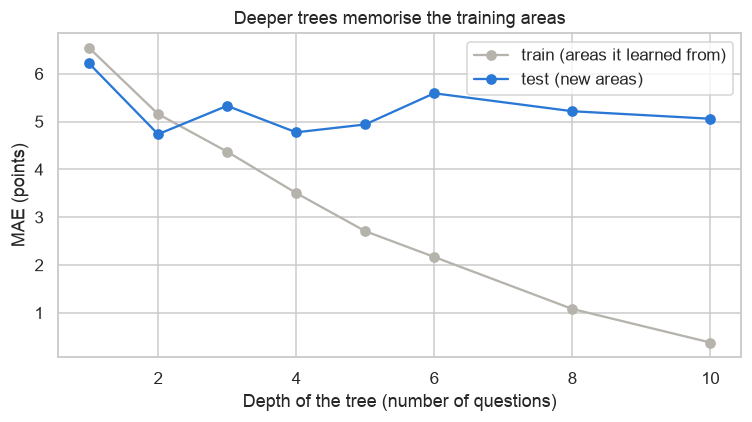

depth,1,2,3,4,5,6,8,10
train MAE,6.54,5.16,4.37,3.51,2.71,2.17,1.08,0.38
test MAE,6.22,4.74,5.33,4.77,4.94,5.59,5.22,5.06


In [7]:
depths = [1, 2, 3, 4, 5, 6, 8, 10]
depth_rows = []
for depth in depths:
    tree = build_pipeline(DecisionTreeRegressor(max_depth=depth, random_state=0)).fit(X_train, y_train)
    depth_rows.append({"depth": depth,
                       "train MAE": mean_absolute_error(y_train, tree.predict(X_train)),
                       "test MAE": mean_absolute_error(y_test, tree.predict(X_test))})
depth_table = pd.DataFrame(depth_rows).set_index("depth")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_table.index, depth_table["train MAE"], marker="o", color=GREY, label="train (areas it learned from)")
ax.plot(depth_table.index, depth_table["test MAE"], marker="o", color=BLUE, label="test (new areas)")
ax.set(xlabel="Depth of the tree (number of questions)", ylabel="MAE (points)",
       title="Deeper trees memorise the training areas")
ax.legend()
plt.tight_layout()
plt.show()
depth_table.round(2).T

**How to read the chart:** the grey line (train) keeps going down: with 10 questions the tree is off by only 0.4 points on the areas it learned from. The blue line (test) is best at depth 2 (4.7 points), then goes up and down around 5. Deep trees create tiny groups of 1 or 2 areas and memorise them: that's **overfitting**. With only 304 training areas, a single tree has little to learn from.

### 7b. The best tree, chosen by GridSearchCV

**What this step does:** GridSearchCV tries every combination of `max_depth` (2 to 8) and `min_samples_leaf` (at least 1, 5, 10 or 20 areas per leaf) and keeps the one with the lowest cross-validation MAE. It only uses the training areas: the test areas stay untouched.

In [8]:
tree_model = tune(DecisionTreeRegressor(random_state=0),
                  {"model__max_depth": [2, 3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10, 20]})
tree_pred = evaluate("Decision Tree – tuned", tree_model)

Best settings: {'max_depth': 5, 'min_samples_leaf': 1} | cross-validation MAE 4.36
Decision Tree – tuned: test MAE 4.94 | RMSE 7.65 | R² 0.458 | train MAE 2.71


**How to read the result:** cross-validation picks depth 5 with 1 area per leaf (CV MAE 4.36). On the test areas the tree is off by **4.94 points**: better than the baseline (8.2) but clearly worse than the straight line (3.39). Its train MAE (2.71) is much lower than its test MAE: it still memorises. A single tree is a weak model here.

**Why does the choice of GridSearchCV (depth 5) differ from the best depth on the test chart (depth 2)?** Because GridSearchCV is not allowed to look at the test areas. That is correct: choosing settings with the test set would make the test score too optimistic.

### 7c. Drawing a small tree

**What this step does:** trains a tree with only 3 questions and draws it. How to read each box:
- first line: the question. Yes (True) → left box, no (False) → right box
- `squared_error`: how spread out the Leave shares are in the box (lower = areas more alike)
- `samples`: how many training areas are in the box
- `value`: the prediction for this box = the average Leave share of those areas (in %)
- colour: darker orange = higher predicted Leave share

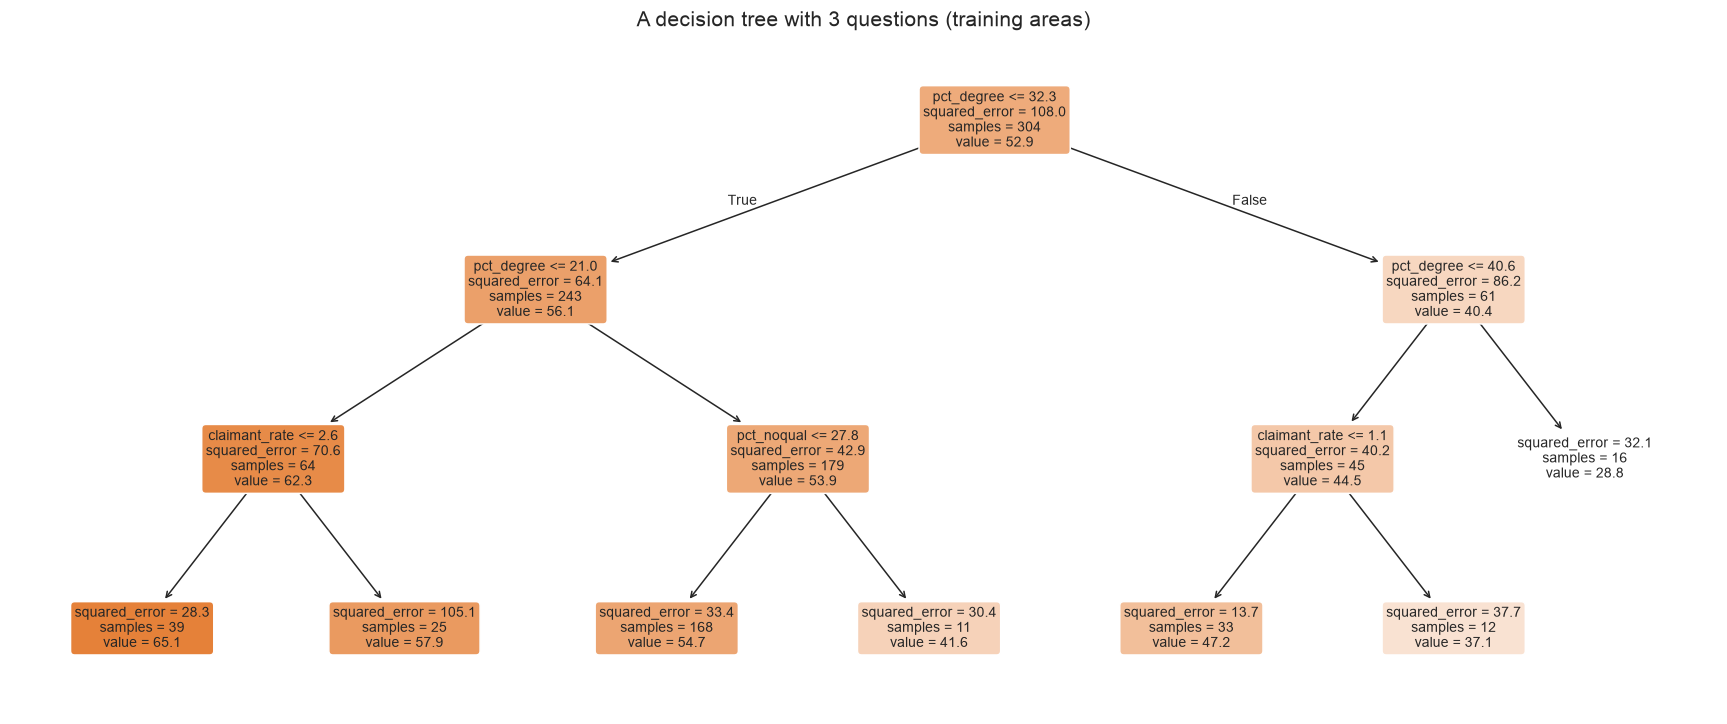

In [9]:
small_tree = build_pipeline(DecisionTreeRegressor(max_depth=3, min_samples_leaf=10, random_state=0)).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(small_tree.named_steps["model"], feature_names=FEATURES, filled=True, rounded=True,
          precision=1, fontsize=9, ax=ax)
ax.set_title("A decision tree with 3 questions (training areas)", fontsize=14)
plt.show()

**How to read the tree (from the top):**
- **Question 1: is the graduate share 32.3% or less?** 243 areas say yes (average 56.1% Leave), 61 say no (40.4%). The most useful clue is education.
- **Question 2 asks about graduates again:** fewer than 21% graduates → 62.3% Leave; more than 40.6% → 28.8% (16 areas, mostly London boroughs, Oxford, Cambridge...).
- **Question 3 refines** with the claimant rate and "no qualifications".
- **A box worth noticing:** "graduates between 21% and 32%, and more than 27.8% with no qualification" → **41.6% Leave**. 9 of its 11 areas are **Scottish councils** (Glasgow, South Lanarkshire, Midlothian...). Scottish councils have a high "no qualification" share for their graduate level, so the tree uses this feature as a **hidden way to spot Scotland**. That only works because Scottish councils are in the training set. In section 13, when the model has never seen Scotland, this trick disappears.

The tree tells the same story as notebook 02, in the form of simple rules: **education first**.

## 8. Random Forest

**What it does:** trains many trees (here 300), each on a random sample of the training areas, and averages their predictions. One tree overfits; the average of many different trees is much more stable. The "random" part: at each question, a tree may only choose among a random part of the features (`max_features`).

**Settings tried:** `max_features` (a third, 60% or all of the features at each question) and `min_samples_leaf` (1, 3 or 5 areas per leaf).

In [10]:
forest = tune(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
              {"model__max_features": [0.33, 0.6, 1.0], "model__min_samples_leaf": [1, 3, 5]})
forest_pred = evaluate("Random Forest – tuned", forest)

Best settings: {'max_features': 1.0, 'min_samples_leaf': 1} | cross-validation MAE 4.03
Random Forest – tuned: test MAE 3.66 | RMSE 5.15 | R² 0.755 | train MAE 1.45


**How to read the result:** the best version uses all the features at each question and 1 area per leaf (CV MAE 4.03, better than the single tree's 4.36). On the test areas: **3.67 points**, much better than the single tree (4.94), but still a little behind the straight line (3.39). Its train MAE (1.46) is low: the forest remembers the training areas, but the averaging keeps the test error low.

## 9. Gradient Boosting

**What it does:** builds small trees **one after the other**. Each new tree tries to fix the mistakes left by the trees before it. The **learning rate** controls how much each tree corrects (small = careful, needs more trees).

**Settings tried:** the number of trees (100 or 300), the learning rate (0.03 or 0.1) and the depth of each tree (2, 3 or 4).

In [11]:
boosting = tune(GradientBoostingRegressor(random_state=0),
                {"model__n_estimators": [100, 300], "model__learning_rate": [0.03, 0.1],
                 "model__max_depth": [2, 3, 4]})
boosting_pred = evaluate("Gradient Boosting – tuned", boosting)

Best settings: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300} | cross-validation MAE 4.03
Gradient Boosting – tuned: test MAE 3.71 | RMSE 5.13 | R² 0.756 | train MAE 0.95


**How to read the result:** the best version uses 300 trees of depth 4 with a careful learning rate (0.03). Test MAE **3.71**: practically tied with the Random Forest (3.67). Its train MAE (0.95) is very low: it fits the training areas closely.

## 10. Class technique 1: KNN, with and without scaling

**What KNN does:** to predict an area, it finds the K most similar training areas (its "neighbours" in the data, not on the map) and averages their Leave shares. "Similar" is a distance computed column by column, so **the scale of each column matters**.

**What this step does:** tries 3 options, like last week: no scaling, MinMaxScaler (like in class), StandardScaler. For each, GridSearchCV picks the number of neighbours K and whether closer neighbours count more (`weights="distance"`).

In [12]:
knn_rows = []
knn_models = {}
for scaler in [None, "minmax", "standard"]:
    print(f"Scaling: {scaler or 'none'}")
    knn = tune(KNeighborsRegressor(), {"model__n_neighbors": [3, 5, 10, 20], "model__weights": ["uniform", "distance"]},
               scaler=scaler)
    knn_models[scaler or "none"] = knn
    knn_rows.append({"scaling": scaler or "none", "test MAE": mean_absolute_error(y_test, knn.predict(X_test))})
pd.DataFrame(knn_rows).set_index("scaling").round(2)

Scaling: none
Best settings: {'n_neighbors': 5, 'weights': 'distance'} | cross-validation MAE 5.90
Scaling: minmax
Best settings: {'n_neighbors': 5, 'weights': 'distance'} | cross-validation MAE 4.83
Scaling: standard
Best settings: {'n_neighbors': 5, 'weights': 'distance'} | cross-validation MAE 4.66


,test MAE
scaling,
none,4.95
minmax,3.59
standard,3.52


**How to read the result:**
- **No scaling: 4.95 points.** Pay is in pounds (400 to 900) while the other features are percentages, so the distance is almost only about pay. The education features, the most useful ones, barely count.
- **MinMaxScaler: 3.59, StandardScaler: 3.52.** Once every column has the same scale, they all count, and KNN becomes as good as the Random Forest.

Lesson: here **scaling helps a lot, as in class (California housing)**. Last week it was the opposite, because one feature (the previous score) was the only clue that mattered. Scaling makes all features equal: it helps when they are all useful, it hurts when one feature dominates.

We keep the StandardScaler version in the comparison. Note: its train MAE is 0, because with `weights="distance"` each training area is its own closest neighbour. That is normal for KNN and is not a sign of a good model; only the test error counts.

In [13]:
knn_pred = evaluate("KNN – scaled", knn_models["standard"])

KNN – scaled: test MAE 3.52 | RMSE 4.76 | R² 0.790 | train MAE 0.00


## 11. Class technique 2: the correlation heatmap and feature selection

**What this step does:** computes the correlation between every pair of features and the target, on the training areas only, and draws it as a heatmap. Signs are removed (absolute values): for feature selection only the strength matters. Only one triangle is shown (the other half is a mirror copy).

**The rule from class:**
1. drop features whose link with the target is weak (|r| < 0.3);
2. when two features are almost copies of each other (|r| > 0.85), keep only the one most linked to the target.

Then we retrain the Linear Regression on the selected features and compare.

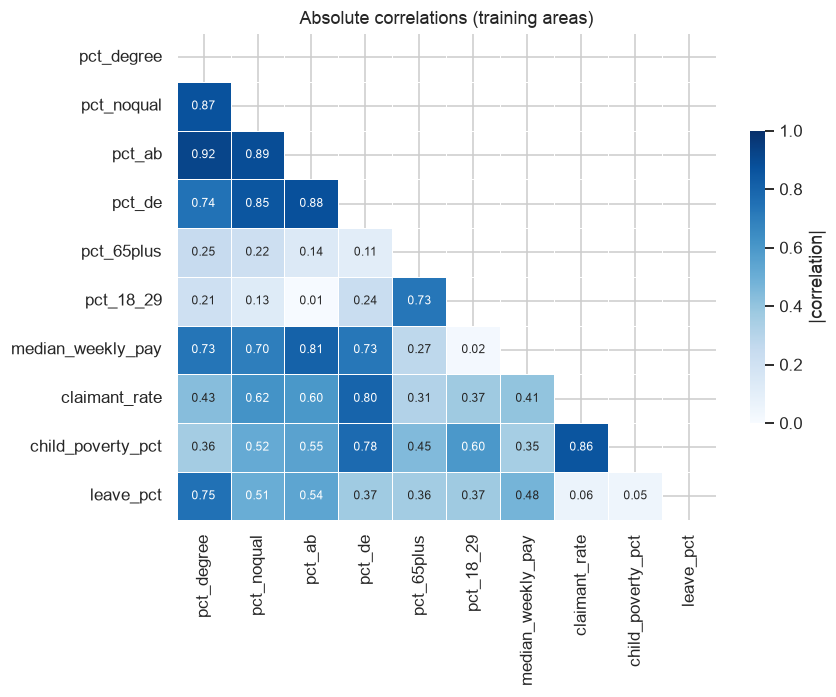

Link with the target: {'pct_degree': 0.75, 'pct_ab': 0.54, 'pct_noqual': 0.51, 'median_weekly_pay': 0.48, 'pct_18_29': 0.37, 'pct_de': 0.37, 'pct_65plus': 0.36, 'claimant_rate': 0.06, 'child_poverty_pct': 0.05}
Selected features: ['pct_degree', 'median_weekly_pay', 'pct_18_29', 'pct_de', 'pct_65plus']
Linear Regression, all 9 features: test MAE 3.39
Linear Regression, 5 selected features: test MAE 3.66


In [14]:
train_table = X_train.assign(leave_pct=y_train)
corr = train_table.corr().abs()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), vmin=0, vmax=1, cmap="Blues", annot=True,
            fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.6, "label": "|correlation|"}, ax=ax)
ax.set_title("Absolute correlations (training areas)")
plt.tight_layout()
plt.show()

# Rule 1: keep features with |r| >= 0.3 with the target
link = corr[TARGET].drop(TARGET).sort_values(ascending=False)
selected = [f for f in link.index if link[f] >= 0.3]
# Rule 2: drop a feature if it is a near-copy (|r| > 0.85) of a feature more linked to the target
for f in list(selected):
    stronger = [g for g in selected if link[g] > link[f]]
    if any(corr.loc[f, g] > 0.85 for g in stronger):
        selected.remove(f)
print("Link with the target:", link.round(2).to_dict())
print("Selected features:", selected)

linear_selected = build_pipeline(LinearRegression(), scaler="standard").fit(X_train[selected], y_train)
selected_mae = mean_absolute_error(y_test, linear_selected.predict(X_test[selected]))
print(f"Linear Regression, all 9 features: test MAE {scores['Linear Regression']['test MAE']:.2f}")
print(f"Linear Regression, {len(selected)} selected features: test MAE {selected_mae:.2f}")

**How to read the heatmap and the result:**
- The bottom row shows the link with the target: strongest for the graduate share (0.75), then social grade AB (0.54), no qualifications (0.51) and pay (0.48). Claimant rate and child poverty have almost no straight-line link with Leave (0.06 and 0.05): the same result as the KPIs in notebook 02.
- The dark squares between education and social grade (degree–AB 0.92, degree–no qualification 0.8…) show the near-copies.
- The rule keeps **5 features**: graduates, pay, 18-29, social grade DE and 65+. It drops claimant rate and child poverty (weak link), and AB and no qualifications (near-copies of the graduate share).
- With these 5 features, the Linear Regression is **worse**: 3.66 points instead of 3.39. Like last week, features that look weak one by one still help in combination. Claimant rate, for example, has almost no link alone, but it is the second most useful feature once education is known (section 16). **We keep all 9 features.**

## 12. The comparison on the random test set

,test MAE,test RMSE,test R²,train MAE,gap (test − train MAE)
Linear Regression,3.39,4.37,0.82,3.72,-0.32
KNN – scaled,3.52,4.76,0.79,0.00,3.52
Random Forest – tuned,3.66,5.15,0.75,1.45,2.21
Gradient Boosting – tuned,3.71,5.13,0.76,0.95,2.76
Decision Tree – tuned,4.94,7.65,0.46,2.71,2.23
Baseline: the average,8.17,10.44,-0.01,8.12,0.04


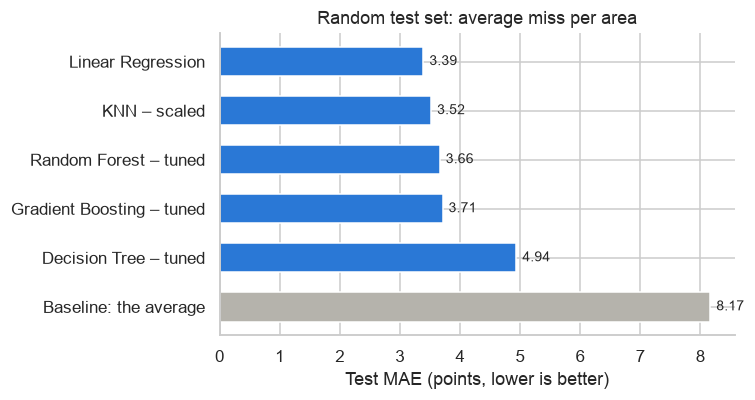

In [15]:
comparison = pd.DataFrame(scores).T
comparison["gap (test − train MAE)"] = comparison["test MAE"] - comparison["train MAE"]
comparison = comparison.sort_values("test MAE")
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
order = comparison["test MAE"].sort_values(ascending=False)
ax.barh(order.index, order.values, color=[GREY if "Baseline" in n else BLUE for n in order.index], height=0.6)
for i, v in enumerate(order.values):
    ax.text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=9)
ax.set(xlabel="Test MAE (points, lower is better)", title="Random test set: average miss per area")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**How to read the table and the chart:**
- **Every model beats the baseline by far** (8.2 → 3.4 to 4.9 points): the population of an area tells us a lot about its vote.
- **Linear Regression is the best on this test (3.39)**, then KNN scaled (3.52), Random Forest (3.67) and Gradient Boosting (3.71). The single tree is last (4.94).
- With only 380 areas and a vote that follows education almost in a straight line, a simple model is hard to beat.

**But this test is too easy and too small:** only 76 areas, and only 2 Scottish councils. It doesn't answer our real question: what happens in a place the model knows little about? Section 13 does the hard test.

## 13. The hard test: predict a region the model has never seen

**Why:** notebook 02 showed (Moran's I = 0.66) that **neighbouring areas vote alike**. With a random split, a test area almost always has neighbours in the training set, which makes the test look too good. The fair question is: "if the model has never seen **any** Scottish council, can it predict Scotland from the population alone?"

**What this step does:** **LeaveOneGroupOut** with the 11 regions as groups. The model learns on 10 regions and predicts the 11th; this is repeated 11 times, so every area gets **one prediction made without its region**. `cross_val_predict` does this in one line. We use the settings already chosen above for each model.

This is the same test as the feasibility check of 3 November (baseline RMSE 10.85, demographics 7.50).

In [16]:
regions = areas["region"]
region_cv = LeaveOneGroupOut()
print("Number of regions (= number of rounds):", regions.nunique())

held_out_models = {
    "Baseline: the average": baseline,
    "Linear Regression": linear,
    "Decision Tree – tuned": tree_model,
    "Random Forest – tuned": forest,
    "Gradient Boosting – tuned": boosting,
    "KNN – scaled": knn_models["standard"],
}
held_out_pred = pd.DataFrame(index=areas.index)
for name, model in held_out_models.items():
    held_out_pred[name] = cross_val_predict(model, X, y, groups=regions, cv=region_cv, n_jobs=-1)

held_out_errors = held_out_pred.rsub(y, axis=0)       # real − predicted (negative = less Leave than expected)
held_out_scores = pd.DataFrame({
    "MAE": held_out_errors.abs().mean(),
    "RMSE": np.sqrt((held_out_errors ** 2).mean()),
    "R²": [r2_score(y, held_out_pred[n]) for n in held_out_pred],
}).sort_values("RMSE")
held_out_scores.round(2)

Number of regions (= number of rounds): 11


,MAE,RMSE,R²
Random Forest – tuned,4.59,6.69,0.59
Gradient Boosting – tuned,4.61,6.83,0.57
Linear Regression,5.20,7.52,0.48
Decision Tree – tuned,5.31,7.81,0.44
KNN – scaled,5.45,7.85,0.43
Baseline: the average,8.44,10.85,-0.09


**How to read the result:**
- All the errors are **bigger** than on the random test: predicting an unknown region is harder.
- The baseline RMSE is **10.85** and the Linear Regression **7.52**: the same numbers as the feasibility check (10.85 and 7.50), so the result is solid.
- Now the **tree models win**: Random Forest RMSE **6.68**, Gradient Boosting 6.83, against 7.52 for the straight line. Section 14 shows why: it's London.

### 13b. The error region by region

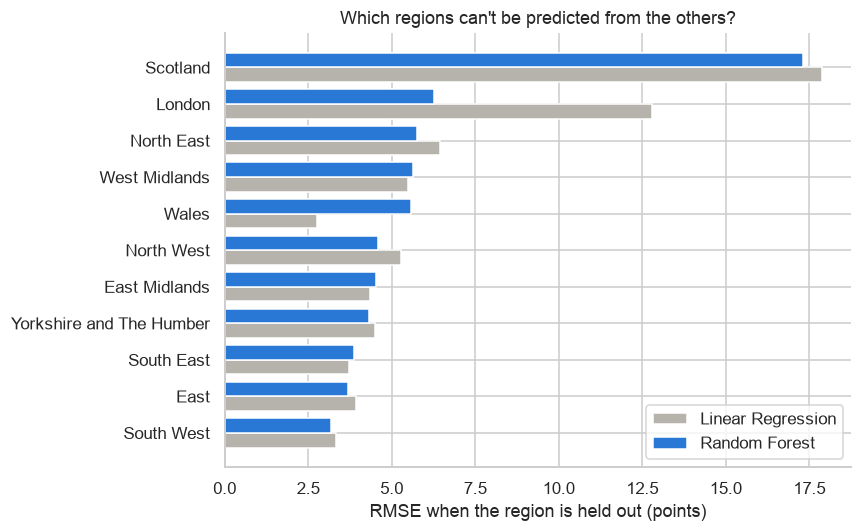

,Baseline: the average,Linear Regression,Random Forest – tuned,Gradient Boosting – tuned
region,,,,
South West,6.0,3.3,3.2,3.0
East,10.4,3.9,3.7,4.5
South East,7.7,3.7,3.9,3.2
Yorkshire and The Humber,9.7,4.5,4.3,5.5
East Midlands,10.1,4.3,4.5,4.4
North West,7.4,5.3,4.6,4.4
Wales,5.4,2.8,5.6,5.4
West Midlands,10.2,5.5,5.6,5.9
North East,8.7,6.4,5.7,6.9


In [17]:
by_region = held_out_errors.groupby(regions).apply(lambda e: np.sqrt((e ** 2).mean()))
by_region = by_region[["Baseline: the average", "Linear Regression", "Random Forest – tuned", "Gradient Boosting – tuned"]]
by_region = by_region.sort_values("Random Forest – tuned")

fig, ax = plt.subplots(figsize=(8, 5))
rows = np.arange(len(by_region))
ax.barh(rows - 0.2, by_region["Linear Regression"], height=0.4, color=GREY, label="Linear Regression")
ax.barh(rows + 0.2, by_region["Random Forest – tuned"], height=0.4, color=BLUE, label="Random Forest")
ax.set_yticks(rows, by_region.index)
ax.set(xlabel="RMSE when the region is held out (points)", title="Which regions can't be predicted from the others?")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
by_region.round(1)

**How to read the chart:**
- In most regions the models miss by about **3 to 6 points** (RMSE): learning from the other regions works well. Wales is the one place where the straight line (2.8) clearly beats the forest (5.6).
- **Scotland is the big failure: about 17-18 points with every model.** No model, simple or complex, can predict Scotland from the rest of Great Britain.
- **London:** the straight line misses by 12.8 points, the Random Forest by only 6.2. Section 14 explains the difference.

## 14. Where the model fails: Scotland and London

**What this step does:** uses the held-out-region predictions to measure, for each group:
- the **average error** (with its sign): negative = the model expected **more** Leave than the real result;
- the **average miss** (without the sign).

Then a scatter plot (real vs predicted) and the 10 biggest misses.

average error (signed)                       average miss (MAE)  \
                Linear Regression Random Forest – tuned  Linear Regression   
group                                                                        
London                       10.9                  -0.9               10.9   
Rest of GB                    0.4                   1.3                3.4   
Scotland                    -16.8                 -16.2               16.8   

                                  
           Random Forest – tuned  
group                             
London                       5.2  
Rest of GB                   3.4  
Scotland                    16.2

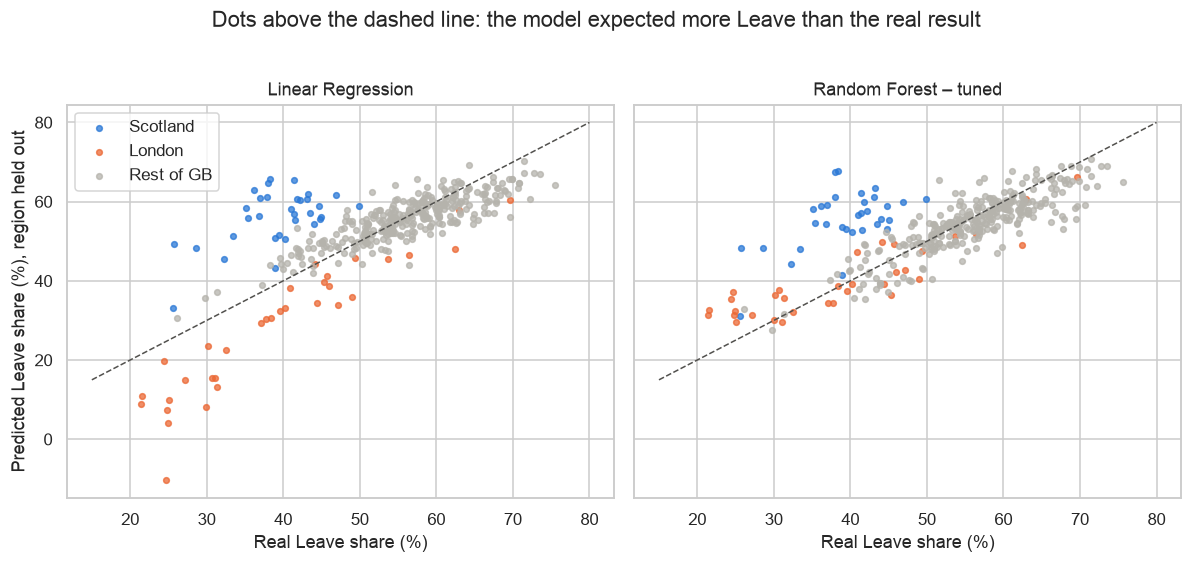

In [18]:
models_to_show = ["Linear Regression", "Random Forest – tuned"]
group_table = pd.concat({
    "average error (signed)": held_out_errors[models_to_show].groupby(areas["group"]).mean(),
    "average miss (MAE)": held_out_errors[models_to_show].abs().groupby(areas["group"]).mean(),
}, axis=1)
display(group_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, name in zip(axes, models_to_show):
    for group, colour in COLOURS.items():
        mask = areas["group"] == group
        ax.scatter(y[mask], held_out_pred.loc[mask, name], s=14, alpha=0.75, color=colour, label=group)
    ax.plot([15, 80], [15, 80], color=DARK, linestyle="--", linewidth=1)
    ax.set(xlabel="Real Leave share (%)", title=name)
axes[0].set_ylabel("Predicted Leave share (%), region held out")
axes[0].legend()
plt.suptitle("Dots above the dashed line: the model expected more Leave than the real result", y=1.02)
plt.tight_layout()
plt.show()

**How to read the table and the chart:**
- **Scotland: about −17 points with both models.** Every Scottish dot sits far above the dashed line: the model expects Scottish councils to vote like English areas with the same population (about 55% Leave), but they voted about 38%. This is not a problem of model choice: **the population alone can't explain Scotland.** It matches notebook 02 (Scotland −15.5 points in model C) and notebook 03 (a **level shift**: the same drivers, at a lower Leave level).
- **London: +10.9 with the straight line, −0.9 with the Random Forest.** London has the most graduates of all. A straight line keeps going down ("more graduates → always less Leave") and, when it has never seen London, predicts levels below anything seen elsewhere: some boroughs get a prediction under 10%, one is even **below 0%**, which is impossible. A tree can't go beyond the values it has seen: for London it predicts the Leave share of the most educated areas it knows. So London is **not** a real failure: it's a problem of the straight line **extrapolating**.
- **Rest of GB:** an average miss of about 3.4 points with both models.

In [19]:
final_name = "Random Forest – tuned"
biggest = areas[["area", "region", "leave_pct"]].assign(
    predicted=held_out_pred[final_name], error=held_out_errors[final_name])
biggest = biggest.reindex(biggest["error"].abs().sort_values(ascending=False).index).head(10)
biggest.round(1)

,area,region,leave_pct,predicted,error
351,West Dunbartonshire,Scotland,38.0,67.5,-29.5
355,North Lanarkshire,Scotland,38.3,67.8,-29.5
336,Midlothian,Scotland,37.9,61.1,-23.2
350,Renfrewshire,Scotland,35.2,58.1,-22.9
335,Inverclyde,Scotland,36.2,59.0,-22.8
330,East Renfrewshire,Scotland,25.7,48.3,-22.6
344,South Lanarkshire,Scotland,36.9,59.3,-22.3
328,East Ayrshire,Scotland,41.4,62.2,-20.8
332,Falkirk,Scotland,43.2,63.4,-20.2
356,East Dunbartonshire,Scotland,28.6,48.2,-19.6


**How to read the table:** the 10 biggest misses of the Random Forest (region held out) are **all Scottish councils**, with errors from −20 to −30 points. Most are in the west-central belt around Glasgow (West Dunbartonshire, North Lanarkshire, Renfrewshire, Inverclyde...): working-class areas that look like strong Leave areas in England (the model expected 58% to 68% Leave) but voted about 35% to 43%. Notebook 03 showed these are also the councils that voted most **Yes** in 2014.

### 14b. The error map

**What this step does:** colours each area by the error of the Random Forest (region held out): **blue = less Leave than predicted, red = more**. Same map method as notebook 02.

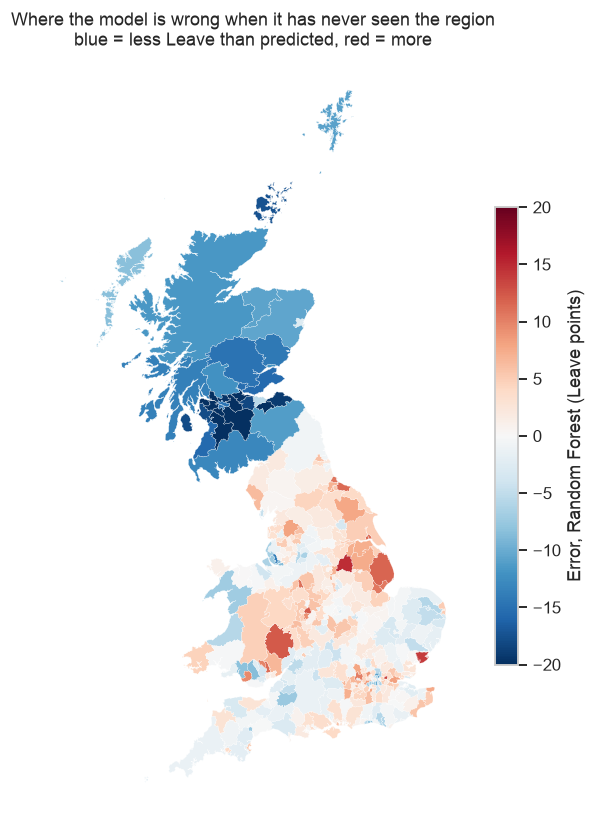

In [20]:
lookup = dict(zip(areas["code"], held_out_errors[final_name]))
polygons, values = [], []
for feature in geo["features"]:
    geometry = feature["geometry"]
    parts = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    for polygon in parts:
        polygons.append(np.asarray(polygon[0]))
        values.append(lookup[feature["properties"]["code"]])

fig, ax = plt.subplots(figsize=(7, 9))
collection = PolyCollection(polygons, array=np.array(values), cmap="RdBu_r", edgecolor="white", linewidth=0.15)
collection.set_clim(-20, 20)
ax.add_collection(collection)
ax.autoscale()
ax.set_aspect(1 / np.cos(np.radians(54)))   # degrees of longitude are shorter in the UK
ax.axis("off")
fig.colorbar(collection, ax=ax, shrink=0.6, label="Error, Random Forest (Leave points)")
ax.set_title("Where the model is wrong when it has never seen the region\nblue = less Leave than predicted, red = more")
plt.show()

**How to read the map:** Scotland is almost entirely **dark blue**: the whole nation voted much less Leave than its population predicts. England and Wales are mostly pale (small errors), with a few red spots (areas that voted more Leave than expected) and blue spots (less). The error is not random: it follows a **border**, not the population.

## 15. Does a political feature fix Scotland? Adding UKIP 2014

**Why:** if Scotland's gap comes from **politics** rather than population, a political feature should reduce it. We add UKIP's share at the 2014 European election and repeat the held-out-region test.

**Careful:** UKIP 2014 is a past vote for a party that wanted to leave the EU. It improves the prediction, but it doesn't **explain** much: it measures the same attitude two years earlier.

In [21]:
FEATURES_UKIP = FEATURES + ["ukip_2014_pct"]
ukip_models = {
    "Linear Regression + UKIP": build_pipeline(LinearRegression(), scaler="standard"),
    "Random Forest + UKIP": build_pipeline(RandomForestRegressor(n_estimators=300, max_features=1.0,
                                                                 random_state=0, n_jobs=-1)),
}
for name, model in ukip_models.items():
    held_out_pred[name] = cross_val_predict(model, areas[FEATURES_UKIP], y, groups=regions, cv=region_cv, n_jobs=-1)
    held_out_errors[name] = y - held_out_pred[name]

compare = ["Linear Regression", "Linear Regression + UKIP", "Random Forest – tuned", "Random Forest + UKIP"]
ukip_table = pd.DataFrame({
    "RMSE, all areas": np.sqrt((held_out_errors[compare] ** 2).mean()),
    "Scotland: average error": held_out_errors[compare][areas["group"] == "Scotland"].mean(),
    "London: average error": held_out_errors[compare][areas["group"] == "London"].mean(),
    "Rest of GB: average miss": held_out_errors[compare][areas["group"] == "Rest of GB"].abs().mean(),
})
ukip_table.round(1)

,"RMSE, all areas",Scotland: average error,London: average error,Rest of GB: average miss
Linear Regression,7.5,-16.8,10.9,3.4
Linear Regression + UKIP,3.7,-6.2,4.3,2.2
Random Forest – tuned,6.7,-16.2,-0.9,3.4
Random Forest + UKIP,4.2,-7.9,0.3,2.4


**How to read the result:**
- With UKIP 2014, the RMSE falls from 7.52 to **3.72** (straight line), the same as the feasibility check (3.75).
- **Scotland's gap shrinks from about −17 to about −6 points (straight line) or −8 (forest), but doesn't disappear.** UKIP was weak in Scotland in 2014, so the model "sees" part of the Scottish difference. The rest is still unexplained.
- Conclusion for the presentation: **Scotland's Remain vote is mostly a political difference, not a population difference.** Notebook 03 adds that it's not a nationalist Remain vote either (SNP and Scottish identity are not linked to Remain).

## 16. Which features does the final model really use? Permutation importance

**Final model:** the **Random Forest** with the 9 population features. On the random test it is close to the best (3.67 vs 3.39), and on the hard test (unknown region) it is the best (RMSE 6.68) and doesn't break in London.

**What this step does:** takes one column of the test areas, shuffles it randomly (so it becomes nonsense), and measures how much worse the predictions get. If the error jumps, the model really relies on that column. Repeated 10 times and averaged. It is safer than the coefficients of section 6, because it works even when features are near-copies.

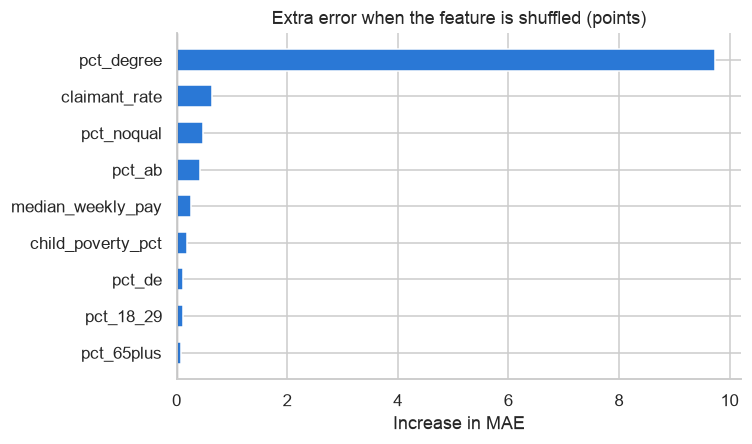

pct_degree           9.73
claimant_rate        0.65
pct_noqual           0.47
pct_ab               0.43
median_weekly_pay    0.26
child_poverty_pct    0.20
pct_de               0.12
pct_18_29            0.11
pct_65plus           0.08
dtype: float64

In [22]:
importance = permutation_importance(forest, X_test, y_test, scoring="neg_mean_absolute_error",
                                    n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.axvline(0, color=DARK, linewidth=0.8)
ax.set(title="Extra error when the feature is shuffled (points)", xlabel="Increase in MAE")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(2)

**How to read the chart:** shuffling the **graduate share** adds about **9.7 points** of error: the model depends on it massively. Everything else adds less than 1 point (claimant rate 0.6, no qualifications 0.5, AB 0.4…). Age adds almost nothing once education is known.

This is the headline of Part 1, found again by a completely different method: **education is the main driver of the Leave vote across areas.**

## 17. "Accuracy" in simple words

**Why:** MAE and RMSE are hard to say in a presentation. Like last week, we translate them into simple percentages, using the held-out-region predictions of the final model (the honest test):
- **within 2 / within 5 points:** how often the prediction is that close to the real result;
- **right side:** how often the model gets the majority right (Leave above or below 50%).

In [23]:
def simple_accuracy(predictions, mask=None):
    mask = np.ones(len(y), dtype=bool) if mask is None else mask
    real, pred = y[mask], predictions[mask]
    miss = (real - pred).abs()
    return {"within 2 points": (miss <= 2).mean(), "within 5 points": (miss <= 5).mean(),
            "right side (Leave/Remain)": ((real > 50) == (pred > 50)).mean(), "areas": int(mask.sum())}


accuracy = pd.DataFrame({
    "Random Forest, all areas": simple_accuracy(held_out_pred[final_name]),
    "Random Forest, Scotland": simple_accuracy(held_out_pred[final_name], areas["group"] == "Scotland"),
    "Random Forest, rest of GB + London": simple_accuracy(held_out_pred[final_name], areas["group"] != "Scotland"),
    "Baseline, all areas": simple_accuracy(held_out_pred["Baseline: the average"]),
}).T
accuracy["areas"] = accuracy["areas"].astype(int)
for col in ["within 2 points", "within 5 points", "right side (Leave/Remain)"]:
    accuracy[col] = accuracy[col].map("{:.0%}".format)
accuracy

,within 2 points,within 5 points,right side (Leave/Remain),areas
"Random Forest, all areas",35%,69%,84%,380
"Random Forest, Scotland",0%,3%,19%,32
"Random Forest, rest of GB + London",39%,75%,90%,348
"Baseline, all areas",19%,38%,69%,380


**How to read the table:**
- **Outside Scotland** (348 areas), the model is within 5 points of the real result **75%** of the time (3 times out of 4) and gets the majority right in **91%** of the areas. The baseline only gets 38% within 5 points.
- **In Scotland**, it is within 5 points for only **1 council out of 32 (3%)**, and gets the side right in only **19%** (6 of 32): it predicts Leave majorities where every council voted Remain.
- For the presentation: *"Knowing only its population, the model predicts an English or Welsh area within 5 points 3 times out of 4, and finds the winning side 9 times out of 10. In Scotland it gets the side wrong 8 times out of 10."*

## 18. Save the final model and export for Tableau

**What this step does:**
1. Saves the final Random Forest (preparation + model) with **joblib**, so it can be reused without training again.
2. Saves **`tableau_ml_results.csv`**, one row per area, with the real Leave share, the held-out-region predictions and errors of the main models, and the `group` column.

**How to use it in Tableau:** like the file of notebook 02, open `gb_areas_boundaries.geojson` as a **Spatial file**, add `tableau_ml_results.csv` as a **Text file**, and join them on `code`. Colour the map by `error_rf` with a diverging palette (blue–red, centred on 0) to rebuild the error map of section 14b.

In [24]:
MODELS_DIR = DATA_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(forest, MODELS_DIR / "brexit_random_forest.joblib")
print("Saved", MODELS_DIR / "brexit_random_forest.joblib")

export = areas[["code", "area", "region", "nation", "group", "leave_pct"]].assign(
    pred_baseline=held_out_pred["Baseline: the average"],
    pred_linear=held_out_pred["Linear Regression"],
    pred_rf=held_out_pred[final_name],
    pred_rf_ukip=held_out_pred["Random Forest + UKIP"],
    error_linear=held_out_errors["Linear Regression"],
    error_rf=held_out_errors[final_name],
    error_rf_ukip=held_out_errors["Random Forest + UKIP"],
).round(2)
export.to_csv(DATA_DIR / "tableau_ml_results.csv", index=False)
print("Saved", DATA_DIR / "tableau_ml_results.csv", export.shape)
export.head()

Saved ../data/models/brexit_random_forest.joblib
Saved ../data/tableau_ml_results.csv (380, 13)


,code,area,region,nation,group,leave_pct,pred_baseline,pred_linear,pred_rf,pred_rf_ukip,error_linear,error_rf,error_rf_ukip
0,E06000001,Hartlepool,North East,England,Rest of GB,69.57,52.93,56.16,58.88,67.38,13.40,10.69,2.18
1,E06000002,Middlesbrough,North East,England,Rest of GB,65.48,52.93,55.36,59.75,64.65,10.12,5.73,0.83
2,E06000003,Redcar and Cleveland,North East,England,Rest of GB,66.19,52.93,57.23,54.88,64.60,8.96,11.31,1.59
3,E06000004,Stockton-on-Tees,North East,England,Rest of GB,61.73,52.93,54.75,54.69,58.78,6.97,7.03,2.94
4,E06000005,Darlington,North East,England,Rest of GB,56.18,52.93,51.97,52.93,55.39,4.22,3.26,0.79


## 19. The whole notebook in simple words

1. **Goal:** predict each area's Leave share from its population only, and find where that fails.
2. **Method (same steps as last week):** baseline → Linear Regression → decision tree (depth curve, GridSearchCV, a small tree drawn) → Random Forest → Gradient Boosting → KNN with and without scaling → heatmap and feature selection → comparison → errors by group → importance → simple "accuracy".
3. **Random test (76 areas):** every model beats the baseline by far (8.2 → about 3.4 to 4.9 points). The straight line is the best (3.39): the vote follows education almost in a straight line.
4. **Class techniques:** scaling makes KNN much better (4.95 → 3.52), as in class. Feature selection with the heatmap makes the model slightly worse: we keep all 9 features.
5. **Hard test (a region the model has never seen):** the Random Forest is the best (RMSE 6.68 vs 10.85 for the baseline). The straight line breaks in **London** because it extrapolates; trees don't. Outside Scotland, the forest is within 5 points 3 times out of 4 and finds the winning side 9 times out of 10.
6. **Scotland is the real failure:** about −17 points with every model; the side is wrong in 26 of 32 councils. The population says "about 55% Leave", Scotland voted 38%. All of Scotland is blue on the error map: the error follows a border, not the population.
7. **Adding UKIP 2014** cuts Scotland's gap to about −6 to −8 points: most of the difference is **political**, not demographic.
8. **What matters most:** the graduate share, by far (shuffling it adds about 9.7 points of error).

**Limits:**
- 380 areas is a small dataset for machine learning; the scores move a little with a different random split.
- The results describe **areas, not voters**: we can't say that graduates voted Remain, only that areas with more graduates did.
- UKIP 2014 is a past vote: it helps predict, but it doesn't explain.
- No forecast: the model describes the 2016 vote, it doesn't predict a future one.

**Next:** the Tableau dashboards (with `tableau_ml_results.csv`) and the presentation: *what happened → what explains it → where it breaks (Scotland)*.